<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-02/homework2.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Tarea 2: Neural Networks Driven by Physics and CNNs for RGB Demosaicking

**Fotografia Computacional**  
**Universidad Tecnica Federico Santa Maria**

## Resumen

Se reconstruye una imagen RGB a partir de un mosaico Bayer mediante interpolacion bilineal, OpenCV, una representacion neuronal implicita y una CNN entrenada con varias imagenes Kodak. La CNN se evalua en imagenes no vistas y se aplica posteriormente a una captura DNG real, comparando visualmente sus resultados con el revelado de la camara.

En esta tarea se estudia el problema de reconstruccion de imagenes RGB a partir de mediciones con mosaico Bayer obtenidas desde sensores reales. En particular, se busca comparar metodos clasicos de demosaicking con aproximaciones basadas en redes neuronales, incluyendo representaciones neuronales implicitas y redes convolucionales.


## 1. Enunciado

El objetivo general de la tarea es reconstruir una imagen RGB a partir de una medicion mosaico capturada por un dispositivo electronico, como un telefono, tablet o camara digital. La medicion corresponde a una imagen RAW o DNG generada por un sensor cubierto con un arreglo de filtros de color Bayer.

A partir de esta medicion, se deben implementar y analizar algoritmos de demosaicking basados en:

1. Metodos tradicionales de interpolacion.
2. Representaciones neuronales implicitas.
3. Redes neuronales convolucionales.

Los resultados deben compararse cuantitativa y cualitativamente con una imagen RGB de referencia, por ejemplo la imagen procesada automaticamente por el dispositivo.


## 2. Contexto teorico

Una camara digital usualmente no mide directamente los tres canales de color en cada pixel. En su lugar, el sensor registra una unica intensidad por posicion espacial, filtrada por un patron Bayer. Para un patron Bayer tipo **RGGB**, la distribucion local de filtros puede representarse como

$$
\begin{bmatrix}
R & G \\
G & B
\end{bmatrix}.
$$

Sea

$$
I \in \mathbb{R}^{H \times W \times 3}
$$

la imagen RGB ideal, donde $H$ y $W$ son la altura y el ancho de la imagen. La medicion mosaico puede modelarse como

$$
Y(i,j) = \sum_{c \in \{R,G,B\}} M_c(i,j) I_c(i,j),
$$

donde $M_c$ es una mascara binaria que indica si el canal $c$ fue medido en la posicion $(i,j)$.

El problema de **demosaicking** consiste en estimar una imagen RGB completa

$$
\hat{I} \in \mathbb{R}^{H \times W \times 3}
$$

a partir de la medicion incompleta $Y$.


## 3. Objetivos

Los objetivos especificos de esta tarea son:

1. Obtener o utilizar una imagen RAW/DNG junto con una imagen RGB de referencia.
2. Representar la medicion del sensor como un mosaico Bayer.
3. Reconstruir la imagen RGB usando un metodo clasico de demosaicking.
4. Reconstruir la imagen RGB usando una representacion neuronal implicita.
5. Reconstruir la imagen RGB usando una red neuronal convolucional.
6. Comparar los metodos mediante metricas objetivas y observaciones visuales.
7. Analizar el efecto de modificar la arquitectura o estrategia de entrenamiento de las redes.


## 4. Preparacion del entorno

En esta seccion se cargaran las librerias necesarias para trabajar con imagenes, arreglos numericos, visualizacion, metricas y entrenamiento de redes neuronales.

Las implementaciones finales deberian considerar, al menos:

- `numpy` para operaciones numericas.
- `matplotlib` para visualizacion.
- `Pillow` u `OpenCV` para lectura y procesamiento de imagenes.
- `torch` para definir y entrenar redes neuronales.
- `pandas` para organizar los resultados experimentales.


In [2]:
# Dependencias para Google Colab
# En Colab, torch suele venir instalado. Esta celda asegura el resto de paquetes usados en la tarea.
%pip install -q opencv-python scikit-image scipy pillow pandas matplotlib rawpy imageio

# Imports generales
from pathlib import Path
from collections import OrderedDict
import os
import time
import math
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2
from skimage import data
from skimage.transform import resize
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import correlate

try:
    import rawpy
except ImportError:
    rawpy = None

import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


Device: cuda


## 5. Datos de trabajo

Para que la tarea sea justa y clara, se separan dos tipos de experimento:

1. **Experimento controlado con referencia conocida**: se usa una imagen RGB (`demo.jpg`) como referencia, se genera un mosaico Bayer sintetico y se evaluan las reconstrucciones con MSE, PSNR y SSIM. Esta es la parte adecuada para comparar metodos de forma cuantitativa, porque se conoce la imagen RGB antes del mosaico.
2. **Experimento real RAW/DNG**: se usa `demo.dng` para leer una medicion real del sensor, detectar el patron CFA/Bayer y visualizar un revelado basico. En esta parte `demo.jpg` se usa solo como referencia visual aproximada, porque ya fue procesada por la camara.

Esta separacion es importante: el DNG real no trae una verdad de terreno RGB limpia. Por eso no conviene basar toda la evaluacion cuantitativa en el par DNG/JPG. El experimento controlado permite medir demosaicking en condiciones conocidas, mientras que el DNG conecta el modelo teorico con una captura real.

Los archivos originales `bursts_0006.dng`, `bursts_0006.tiff` y `bursts_0006.jpg` se mantienen solo como referencia de una captura no utilizable. Para esta entrega se usan `demo.dng` y `demo.jpg`, descargados automaticamente desde GitHub.


### Captura real RAW/DNG

En esta seccion se descarga una captura real valida en formato `DNG` junto con su referencia `JPG` procesada por la camara. El objetivo no es entrenar con esta imagen, sino verificar que el notebook puede leer una medicion RAW real, extraer informacion del arreglo CFA/Bayer desde los metadatos y visualizar cualitativamente la diferencia entre la medicion del sensor y una imagen ya procesada por el pipeline interno de la camara.

En Google Colab, las siguientes celdas descargan automaticamente los archivos desde GitHub.


In [3]:
from pathlib import Path
import urllib.request

DATA_DIR = Path("data/raw_demo")
DATA_DIR.mkdir(parents=True, exist_ok=True)

RAW_URL = "https://raw.githubusercontent.com/fralfaro/images/refs/heads/main/demo.dng"
JPG_URL = "https://raw.githubusercontent.com/fralfaro/images/refs/heads/main/demo.jpg"
RAW_PATH = DATA_DIR / "demo.dng"
JPG_PATH = DATA_DIR / "demo.jpg"

for url, out_path in [(RAW_URL, RAW_PATH), (JPG_URL, JPG_PATH)]:
    if not out_path.exists():
        urllib.request.urlretrieve(url, out_path)
    print(f"{out_path}: {out_path.stat().st_size / 1024**2:.2f} MB")


data/raw_demo/demo.dng: 7.99 MB
data/raw_demo/demo.jpg: 1.89 MB


In [4]:
# rawpy permite leer DNG/RAW y hacer un revelado basico.
# En Colab normalmente basta con instalarlo una vez por sesion.
try:
    import rawpy
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rawpy"])
    import rawpy


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import rawpy

with rawpy.imread(str(RAW_PATH)) as raw:
    raw_visible = raw.raw_image_visible.astype(np.float32).copy()
    black = np.array(raw.black_level_per_channel, dtype=np.float32)
    white = float(raw.white_level)
    color_desc = raw.color_desc.decode("ascii")
    raw_pattern = raw.raw_pattern.copy()
    rgb_from_raw = raw.postprocess(
        use_camera_wb=True,
        no_auto_bright=True,
        output_bps=8,
    )

jpg_ref = np.asarray(ImageOps.exif_transpose(Image.open(JPG_PATH)).convert("RGB"))

pattern_letters = np.array(list(color_desc))[raw_pattern]
bayer_pattern = "".join(pattern_letters.ravel())

print("Forma RAW visible:", raw_visible.shape)
print("Forma JPG referencia:", jpg_ref.shape)
print("Descripcion de colores CFA:", color_desc)
print("Patron Bayer/CFA detectado:")
print(pattern_letters)
print("Patron 2x2:", bayer_pattern)
print("Black levels por canal:", black.astype(int).tolist())
print("White level:", int(white))

black_floor = float(np.min(black))
white_display = white
if white_display <= black_floor:
    # Algunos DNG de telefono reportan niveles no lineales; para visualizar y entrenar,
    # se usa un rango robusto basado en percentiles de la medicion visible.
    black_floor, white_display = np.percentile(raw_visible, [1, 99.8])

raw_mosaic_full = raw_visible.copy()
raw_mosaic_full = np.maximum(raw_mosaic_full - black_floor, 0)
raw_mosaic_full = raw_mosaic_full / max(white_display - black_floor, 1)
raw_mosaic_full = np.clip(raw_mosaic_full, 0, 1).astype(np.float32)


Forma RAW visible: (3060, 4080)
Forma JPG referencia: (4080, 3060, 3)
Descripcion de colores CFA: RGBG
Patron Bayer/CFA detectado:
[['G' 'R']
 ['B' 'G']]
Patron 2x2: GRBG
Black levels por canal: [63, 63, 63, 63]
White level: 1023


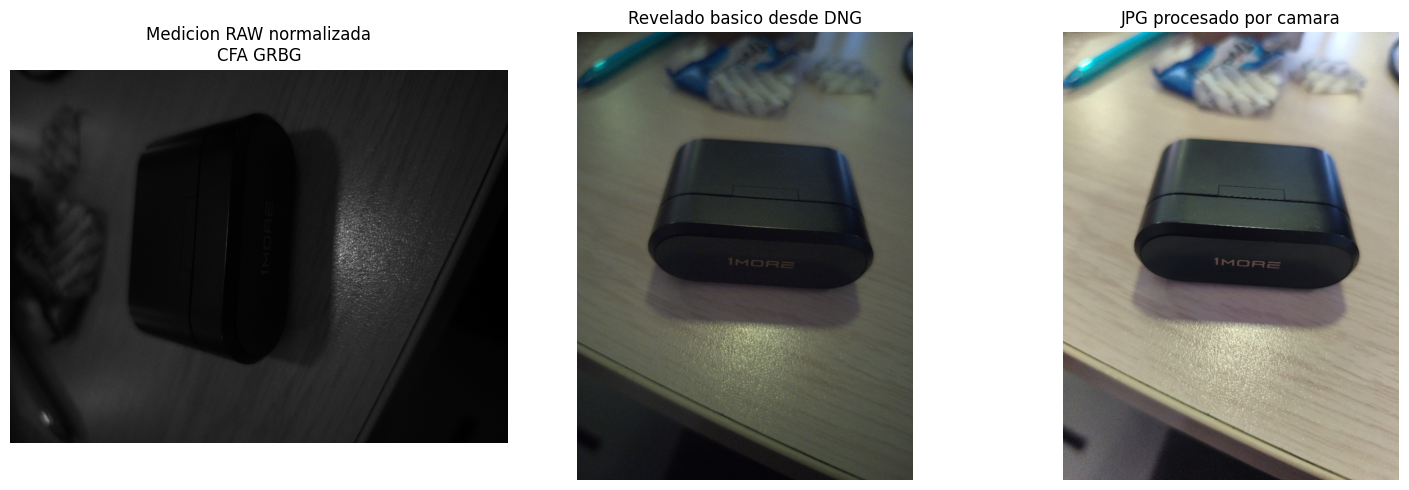

In [6]:
raw_norm = raw_mosaic_full

# Se usa una version reducida para que la visualizacion sea liviana en Colab.
max_side = 1200
scale_raw = max(raw_norm.shape) / max_side
scale_jpg = max(jpg_ref.shape[:2]) / max_side
step_raw = max(1, int(np.ceil(scale_raw)))
step_jpg = max(1, int(np.ceil(scale_jpg)))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(raw_norm[::step_raw, ::step_raw], cmap="gray")
axes[0].set_title(f"Medicion RAW normalizada\nCFA {bayer_pattern}")
axes[0].axis("off")

axes[1].imshow(rgb_from_raw[::step_raw, ::step_raw])
axes[1].set_title("Revelado basico desde DNG")
axes[1].axis("off")

axes[2].imshow(jpg_ref[::step_jpg, ::step_jpg])
axes[2].set_title("JPG procesado por camara")
axes[2].axis("off")

plt.tight_layout()
plt.show()


La captura `demo.dng` corresponde a una medicion real del sensor: contiene una sola intensidad por posicion espacial y los metadatos permiten recuperar el arreglo CFA/Bayer usado por la camara. En cambio, `demo.jpg` ya incluye el procesamiento interno del dispositivo, incluyendo demosaicking, balance de blancos, correccion de color, reduccion de ruido, nitidez, compresion y posiblemente mapeo tonal.

Por eso la comparacion visual no debe interpretarse como una metrica objetiva de demosaicking: el JPG no es una referencia lineal pura del sensor, sino una version procesada para visualizacion. Aun asi, esta seccion completa la validacion cualitativa con una captura RAW/DNG real y muestra como conectar el experimento sintetico con datos capturados por una camara.


## 6. Experimento controlado con `demo.jpg`

La evaluacion principal usa `demo.jpg` como imagen RGB de referencia. A partir de ella se genera un mosaico Bayer sintetico con el mismo patron detectado en `demo.dng`. Asi se mantiene una conexion con la captura real, pero se conserva una referencia RGB conocida para calcular metricas de forma justa.

En este caso,

$$
I_{\text{ref}} = I_{\text{demo.jpg}}.
$$

A partir de esta imagen se construye el mosaico $Y$ usando el patron Bayer detectado desde el DNG. Esta sera la entrada para el metodo bilineal y la INR-SIREN. La CNN se entrenara exclusivamente con varias imagenes del dataset Kodak.


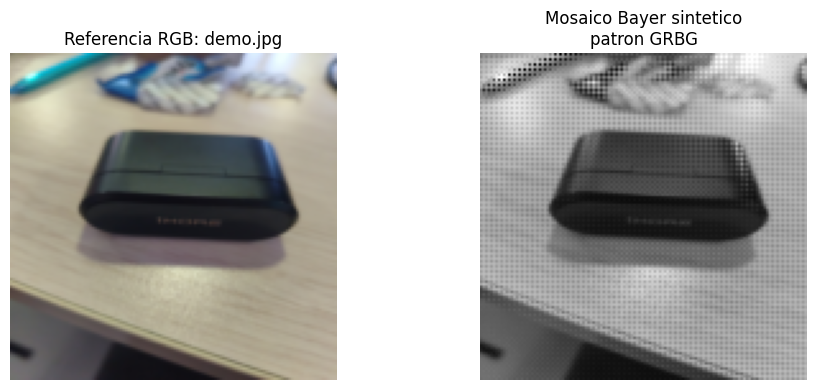

In [7]:
# Preparacion del experimento controlado con demo.jpg
def bayer_masks(height, width, pattern="RGGB"):
    patterns = {
        "RGGB": np.array([[0, 1], [1, 2]]),
        "BGGR": np.array([[2, 1], [1, 0]]),
        "GRBG": np.array([[1, 0], [2, 1]]),
        "GBRG": np.array([[1, 2], [0, 1]]),
    }
    if pattern not in patterns:
        raise ValueError(f"Patron Bayer no soportado: {pattern}")
    tile = patterns[pattern]
    masks = np.zeros((height, width, 3), dtype=np.float32)
    for row in range(2):
        for col in range(2):
            masks[row::2, col::2, tile[row, col]] = 1.0
    return masks

N = 128
rgb_reference = resize(
    jpg_ref.astype(np.float32) / 255.0,
    (N, N, 3),
    anti_aliasing=True,
    preserve_range=True,
).astype(np.float32)
rgb_reference = np.clip(rgb_reference, 0.0, 1.0)

bayer = bayer_masks(N, N, pattern=bayer_pattern)
mosaic = make_bayer_mosaic(rgb_reference, bayer) if "make_bayer_mosaic" in globals() else np.sum(rgb_reference * bayer, axis=-1).astype(np.float32)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB: demo.jpg")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Mosaico Bayer sintetico\npatron {bayer_pattern}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 7. Modelo de mosaico Bayer

Para un patron Bayer de 2 x 2, se definen tres mascaras binarias:

$$
M_R, M_G, M_B \in \{0,1\}^{H \times W}.
$$

Cada mascara indica las posiciones del sensor donde se mide cada canal. En el experimento controlado, la medicion mosaico se construye como

$$
Y = M_R \odot I_R + M_G \odot I_G + M_B \odot I_B,
$$

donde $I$ corresponde a `demo.jpg` normalizada. El patron usado no se elige arbitrariamente: se toma desde los metadatos de `demo.dng`, por eso en esta captura aparece como `GRBG`.


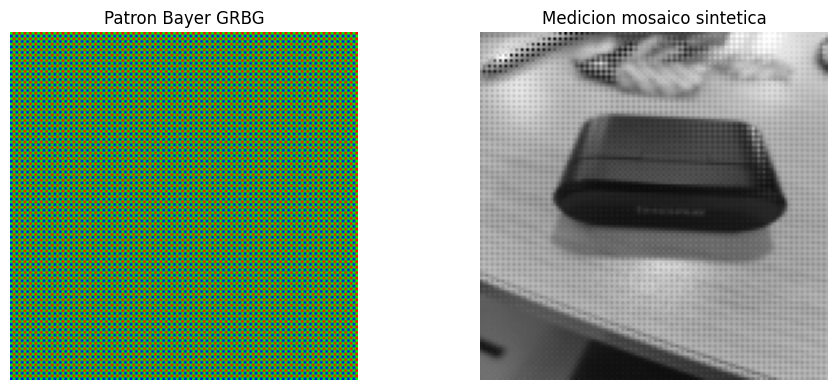

In [8]:
# Mascaras Bayer y medicion mosaico
def bayer_masks(height, width, pattern="RGGB"):
    """Construye mascaras binarias RGB para un patron Bayer de 2x2."""
    patterns = {
        "RGGB": np.array([[0, 1], [1, 2]]),
        "BGGR": np.array([[2, 1], [1, 0]]),
        "GRBG": np.array([[1, 0], [2, 1]]),
        "GBRG": np.array([[1, 2], [0, 1]]),
    }
    if pattern not in patterns:
        raise ValueError(f"Patron Bayer no soportado: {pattern}")
    tile = patterns[pattern]
    masks = np.zeros((height, width, 3), dtype=np.float32)
    for row in range(2):
        for col in range(2):
            masks[row::2, col::2, tile[row, col]] = 1.0
    return masks

def make_bayer_mosaic(rgb_image, masks):
    return np.sum(rgb_image * masks, axis=-1).astype(np.float32)

bayer = bayer_masks(*rgb_reference.shape[:2], pattern=bayer_pattern)
mosaic = make_bayer_mosaic(rgb_reference, bayer)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(bayer)
axes[0].set_title(f"Patron Bayer {bayer_pattern}")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Medicion mosaico sintetica")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 8. Metodo clasico de demosaicking

Como linea base, se debe reconstruir la imagen RGB usando un metodo tradicional. Un enfoque simple consiste en interpolar los valores faltantes de cada canal a partir de las muestras disponibles.

La reconstruccion clasica se denotara como

$$
\hat{I}_{\text{clasico}}.
$$

Esta reconstruccion servira como referencia inicial para evaluar si los metodos neuronales entregan mejoras cuantitativas o visuales.


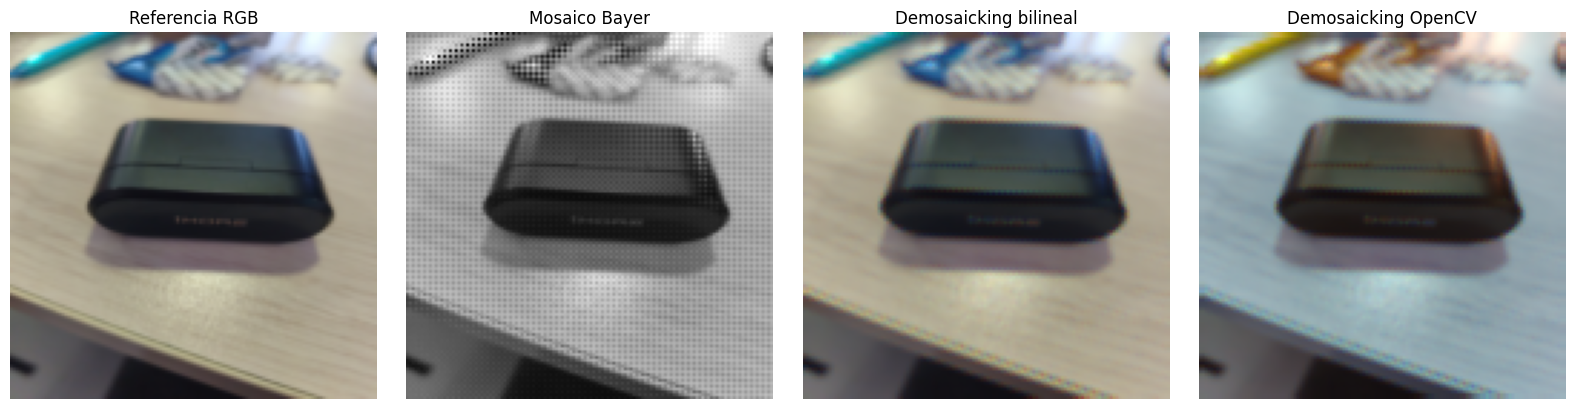

In [9]:
# Demosaicking clasico por interpolacion bilineal
def demosaic_bilinear(mosaic, masks):
    # Los kernels separables estiman los valores faltantes de cada canal.
    kernels = [
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
        np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=np.float32),
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
    ]
    channels = []
    for channel, kernel in enumerate(kernels):
        observed = mosaic * masks[..., channel]
        estimate = correlate(observed, kernel, mode="mirror") / 4.0
        # Conserva exactamente las muestras que el sensor si observo.
        channels.append(np.where(masks[..., channel] > 0, observed, estimate))
    return np.clip(np.stack(channels, axis=-1), 0.0, 1.0).astype(np.float32)

I_hat_classic = demosaic_bilinear(mosaic, bayer)

def demosaic_opencv(mosaic, pattern):
    """Demosaicking bilineal de OpenCV para un patron Bayer dado."""
    # OpenCV entrega BGR con estas conversiones; se invierten los canales
    # al final para mantener el convenio RGB del resto del notebook.
    opencv_codes = {
        "RGGB": cv2.COLOR_BayerRG2BGR,
        "BGGR": cv2.COLOR_BayerBG2BGR,
        "GRBG": cv2.COLOR_BayerGR2BGR,
        "GBRG": cv2.COLOR_BayerGB2BGR,
    }
    if pattern not in opencv_codes:
        raise ValueError(f"Patron Bayer no soportado por OpenCV: {pattern}")
    mosaic_uint16 = np.rint(np.clip(mosaic, 0.0, 1.0) * 65535).astype(np.uint16)
    reconstruction = cv2.cvtColor(mosaic_uint16, opencv_codes[pattern])[..., ::-1]
    return reconstruction.astype(np.float32) / 65535.0

I_hat_opencv = demosaic_opencv(mosaic, bayer_pattern)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mosaico Bayer")
axes[2].imshow(I_hat_classic)
axes[2].set_title("Demosaicking bilineal")
axes[3].imshow(I_hat_opencv)
axes[3].set_title("Demosaicking OpenCV")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 9. Representacion neuronal implicita

Una representacion neuronal implicita modela una senal como una funcion continua parametrizada por una red neuronal. En este caso, se busca aprender una funcion

$$
f_\theta: \mathbb{R}^3 \rightarrow \mathbb{R},
$$

donde la entrada corresponde a una coordenada espacial y un indice de canal,

$$
(x, y, c),
$$

y la salida corresponde a una intensidad estimada.

El entrenamiento utiliza solamente las posiciones observadas en el mosaico Bayer. La funcion de perdida puede escribirse como

$$
\mathcal{L}(\theta) = \frac{1}{|\Omega|} \sum_{(i,j,c) \in \Omega}
\left( f_\theta(x_i, y_j, c) - Y(i,j) \right)^2,
$$

donde $\Omega$ es el conjunto de muestras disponibles en el sensor.

La reconstruccion obtenida se denotara por

$$
\hat{I}_{\text{INR}}.
$$


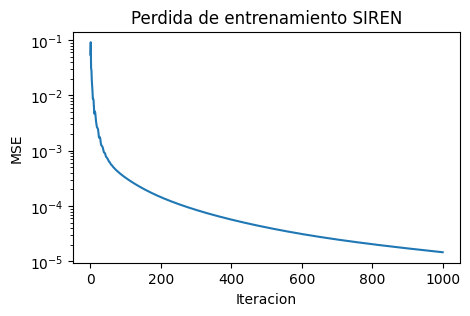

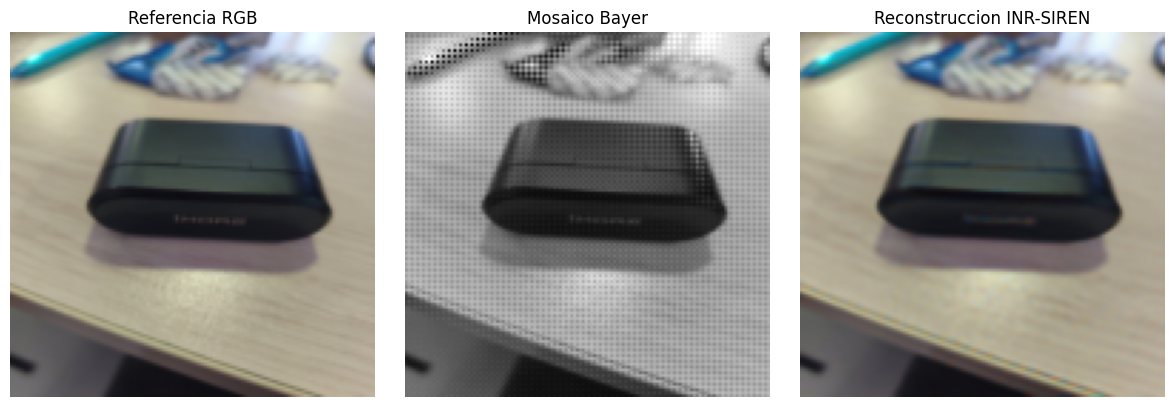

In [10]:
# Representacion neuronal implicita tipo SIREN
class SineLayer(nn.Module):
    def __init__(self, in_features, out_features, omega_0=30.0, is_first=False):
        super().__init__()
        self.omega_0 = omega_0
        self.linear = nn.Linear(in_features, out_features)
        with torch.no_grad():
            if is_first:
                self.linear.weight.uniform_(-1 / in_features, 1 / in_features)
            else:
                bound = np.sqrt(6 / in_features) / omega_0
                self.linear.weight.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))

class Siren(nn.Module):
    def __init__(self, hidden_features=256, hidden_layers=3, out_features=3):
        super().__init__()
        layers = [SineLayer(2, hidden_features, is_first=True)]
        layers += [SineLayer(hidden_features, hidden_features) for _ in range(hidden_layers)]
        layers += [nn.Linear(hidden_features, out_features)]
        self.net = nn.Sequential(*layers)

    def forward(self, coords):
        return torch.sigmoid(self.net(coords))

def build_spatial_grid(height, width):
    yy, xx = np.meshgrid(
        np.linspace(-1, 1, height, dtype=np.float32),
        np.linspace(-1, 1, width, dtype=np.float32),
        indexing="ij",
    )
    coords = np.stack([xx.ravel(), yy.ravel()], axis=1)
    return torch.from_numpy(coords).float()

def train_siren_from_mosaic(mosaic, masks, hidden_features=256, hidden_layers=3, steps=1000, learning_rate=1e-4):
    height, width = mosaic.shape
    coords = build_spatial_grid(height, width).to(DEVICE)
    mosaic_tensor = torch.from_numpy(mosaic[..., None]).float().to(DEVICE)
    masks_tensor = torch.from_numpy(masks).float().to(DEVICE)
    model = Siren(hidden_features, hidden_layers, out_features=3).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    model.train()
    for step in range(steps):
        rgb_prediction = model(coords).reshape(height, width, 3)
        mosaic_prediction = torch.sum(rgb_prediction * masks_tensor, dim=-1, keepdim=True)
        loss = F.mse_loss(mosaic_prediction, mosaic_tensor)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())

    model.eval()
    with torch.no_grad():
        reconstruction = model(coords).reshape(height, width, 3).cpu().numpy()
    return model, np.clip(reconstruction, 0.0, 1.0).astype(np.float32), history

model_inr, I_hat_inr, loss_history = train_siren_from_mosaic(
    mosaic, bayer, hidden_features=256, hidden_layers=3, steps=1000
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.yscale("log")
plt.title("Perdida de entrenamiento SIREN")
plt.xlabel("Iteracion")
plt.ylabel("MSE")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mosaico Bayer")
axes[2].imshow(I_hat_inr)
axes[2].set_title("Reconstruccion INR-SIREN")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. Red neuronal convolucional

El segundo enfoque neuronal consiste en entrenar una red convolucional que reciba como entrada la medicion mosaico y produzca directamente una imagen RGB.

La entrada se define como

$$
X_{\text{CNN}} = [Y, M_R, M_G, M_B] \in \mathbb{R}^{H \times W \times 4}.
$$

La CNN aprende una funcion

$$
g_\phi: \mathbb{R}^{H \times W \times 4} \rightarrow \mathbb{R}^{H \times W \times 3}.
$$

La CNN se entrena con parches de varias imagenes del dataset Kodak y se evalua sobre imagenes completas no utilizadas durante el entrenamiento. Asi, sus resultados miden capacidad de generalizacion y no solo ajuste a una captura individual.


In [11]:
# Red neuronal convolucional
class ResidualBlock(nn.Module):
    def __init__(self, channels, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
        )

    def forward(self, x):
        return x + self.block(x)

class DemosaicCNN(nn.Module):
    def __init__(self, input_channels=4, hidden_channels=32, num_blocks=4):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Conv2d(input_channels, hidden_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.residual_layers = nn.Sequential(
            *[ResidualBlock(hidden_channels) for _ in range(num_blocks)]
        )
        self.output_layer = nn.Conv2d(hidden_channels, 3, 3, padding=1)

    def forward(self, x):
        features = self.input_layer(x)
        features = self.residual_layers(features)
        return torch.sigmoid(self.output_layer(features))

def sensor_consistency_loss(prediction, input_tensor):
    """Penaliza que la reconstruccion reproduzca la medicion Bayer observada."""
    mosaic_reprojected = torch.sum(prediction * input_tensor[:, 1:4], dim=1, keepdim=True)
    return F.mse_loss(mosaic_reprojected, input_tensor[:, 0:1])


## 10.1. Entrenamiento de la CNN con varias imagenes

La CNN se entrena exclusivamente con varias imagenes del dataset Kodak, siguiendo la idea del notebook `extra/cnnDemosaicing.ipynb`. La evaluacion se realiza sobre imagenes no vistas para medir generalizacion.

La division se hace de esta forma:

- 20 imagenes Kodak para entrenamiento.
- 4 imagenes Kodak para prueba.
- Cada imagen se divide en parches de 64 x 64.
- Los parches de prueba provienen de imagenes completas que no fueron usadas durante el entrenamiento.

Asi, cuando se reportan metricas de la CNN sobre Kodak, esas metricas corresponden a imagenes no vistas por el modelo.


Imagenes de entrenamiento: 20
Imagenes de prueba: 4
Parches de entrenamiento: 1920
Parches de prueba: 384
Epoca 01/6: perdida = 0.017140
Epoca 02/6: perdida = 0.006243
Epoca 03/6: perdida = 0.002852
Epoca 04/6: perdida = 0.001855
Epoca 05/6: perdida = 0.001261
Epoca 06/6: perdida = 0.000898
MSE promedio en parches de prueba Kodak: 0.000795


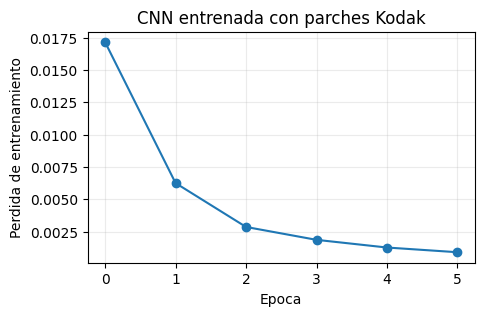

In [12]:
# Dataset Kodak para entrenamiento supervisado multi-imagen
# Rutas para ejecucion local o Colab
try:
    from google.colab import files  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "tareas" / "tarea-02").exists() and Path.cwd().name == "tarea-02":
    REPO_ROOT = Path.cwd().parents[1]

TASK_DIR = REPO_ROOT / "tareas" / "tarea-02"
LOCAL_DATASET_DIR = REPO_ROOT / "tareas" / "dataset"
DATA_DIR = Path("/content") if IN_COLAB else TASK_DIR

KODAK_DIR = DATA_DIR / "kodak"
KODAK_DIR.mkdir(exist_ok=True)
KODAK_ZIP = KODAK_DIR / "kodak.zip"
KODAK_URL = "https://arizona.box.com/shared/static/5bk6qar4vgfizmhum8onreu6sp90bz2i"

# El repositorio tambien trae tareas/dataset/01.png ... 24.png; se usa como respaldo local.
def select_local_kodak_paths(dataset_dir):
    if not dataset_dir.exists():
        return []
    selected = []
    for index in range(1, 25):
        candidates = [dataset_dir / f"{index:02d}.png", dataset_dir / f"{index}.png"]
        selected.extend([path for path in candidates if path.exists()][:1])
    return selected

local_kodak_paths = select_local_kodak_paths(LOCAL_DATASET_DIR)
if len(local_kodak_paths) >= 8:
    kodak_paths = local_kodak_paths
else:
    if not list(KODAK_DIR.rglob("kodim*.png")):
        urllib.request.urlretrieve(KODAK_URL, KODAK_ZIP)
        with zipfile.ZipFile(KODAK_ZIP, "r") as zip_ref:
            zip_ref.extractall(KODAK_DIR)
    kodak_paths = sorted(KODAK_DIR.rglob("kodim*.png"))

if len(kodak_paths) < 8:
    raise RuntimeError(f"Se encontraron {len(kodak_paths)} imagenes Kodak; revisa la descarga o tareas/dataset.")

kodak_paths = kodak_paths[:24]
train_paths = kodak_paths[:-4]
test_paths = kodak_paths[-4:]
print(f"Imagenes de entrenamiento: {len(train_paths)}")
print(f"Imagenes de prueba: {len(test_paths)}")

class KodakPatchDataset(Dataset):
    def __init__(self, image_paths, patch_size=64, stride=64, max_patches_per_image=None):
        self.samples = []
        self.patch_size = patch_size
        for path in image_paths:
            image = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
            height, width = image.shape[:2]
            image_samples = []
            for top in range(0, height - patch_size + 1, stride):
                for left in range(0, width - patch_size + 1, stride):
                    image_samples.append(image[top:top + patch_size, left:left + patch_size])
            if max_patches_per_image is not None:
                image_samples = image_samples[:max_patches_per_image]
            self.samples.extend(image_samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        rgb = self.samples[index]
        masks = bayer_masks(self.patch_size, self.patch_size, pattern=bayer_pattern)
        mosaic_patch = make_bayer_mosaic(rgb, masks)
        input_patch = np.concatenate([mosaic_patch[..., None], masks], axis=-1)
        input_tensor = torch.from_numpy(input_patch.transpose(2, 0, 1)).float()
        target_tensor = torch.from_numpy(rgb.transpose(2, 0, 1)).float()
        return input_tensor, target_tensor

train_dataset = KodakPatchDataset(train_paths, patch_size=64, stride=64)
test_dataset = KodakPatchDataset(test_paths, patch_size=64, stride=64)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)
print(f"Parches de entrenamiento: {len(train_dataset)}")
print(f"Parches de prueba: {len(test_dataset)}")

def train_cnn_loader(model, loader, epochs=6, learning_rate=1e-3, physics_weight=0.1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    for epoch in range(epochs):
        epoch_loss = 0.0
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)
            predictions = model(inputs)
            rgb_loss = F.mse_loss(predictions, targets)
            physics_loss = sensor_consistency_loss(predictions, inputs)
            loss = rgb_loss + physics_weight * physics_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * inputs.size(0)
        epoch_loss /= len(loader.dataset)
        history.append(epoch_loss)
        print(f"Epoca {epoch + 1:02d}/{epochs}: perdida = {epoch_loss:.6f}")
    return history

def evaluate_cnn_loader(model, loader):
    model.eval()
    losses = []
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu()
            losses.append(F.mse_loss(predictions, targets).item())
    return float(np.mean(losses))

model_cnn_kodak = DemosaicCNN(input_channels=4, hidden_channels=32, num_blocks=4).to(DEVICE)
kodak_loss_history = train_cnn_loader(model_cnn_kodak, train_loader, epochs=6)
kodak_test_mse = evaluate_cnn_loader(model_cnn_kodak, test_loader)
print(f"MSE promedio en parches de prueba Kodak: {kodak_test_mse:.6f}")

plt.figure(figsize=(5, 3))
plt.plot(kodak_loss_history, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Perdida de entrenamiento")
plt.title("CNN entrenada con parches Kodak")
plt.grid(alpha=0.25)
plt.show()


## 11. Variantes experimentales

Para estudiar el efecto de la arquitectura y de la perdida informada por fisica se comparan tres CNN entrenadas sobre Kodak con el mismo numero de epocas:

| Metodo | Canales ocultos | Bloques residuales | Epocas | Peso fisico |
|---|---:|---:|---:|---:|
| CNN pequena | 16 | 2 | 6 | 0.1 |
| CNN base | 32 | 4 | 6 | 0.1 |
| CNN base sin fisica | 32 | 4 | 6 | 0.0 |

La comparacion se reporta sobre el conjunto de prueba, es decir, sobre parches provenientes de imagenes no vistas durante entrenamiento. Mantener seis epocas en las tres variantes permite atribuir mejor las diferencias a la arquitectura y al peso de la consistencia fisica.


In [13]:
# Variantes de arquitectura y entrenamiento para la CNN Kodak
cnn_experiments = [
    {"nombre": "CNN pequena", "hidden_channels": 16, "num_blocks": 2, "epochs": 6, "physics_weight": 0.1},
    {"nombre": "CNN base", "hidden_channels": 32, "num_blocks": 4, "epochs": 6, "physics_weight": 0.1},
    {"nombre": "CNN base sin fisica", "hidden_channels": 32, "num_blocks": 4, "epochs": 6, "physics_weight": 0.0},
]

def run_cnn_experiment(config):
    start_time = time.perf_counter()
    model = DemosaicCNN(
        input_channels=4,
        hidden_channels=config["hidden_channels"],
        num_blocks=config["num_blocks"],
    ).to(DEVICE)
    history = train_cnn_loader(
        model,
        train_loader,
        epochs=config["epochs"],
        physics_weight=config["physics_weight"],
    )
    test_mse = evaluate_cnn_loader(model, test_loader)
    return {
        "metodo": config["nombre"],
        "canales": config["hidden_channels"],
        "bloques": config["num_blocks"],
        "epocas": config["epochs"],
        "peso fisica": config["physics_weight"],
        "MSE prueba": test_mse,
        "tiempo [s]": time.perf_counter() - start_time,
    }, history

variant_rows = []
variant_histories = {}
for config in cnn_experiments:
    row, history = run_cnn_experiment(config)
    variant_rows.append(row)
    variant_histories[config["nombre"]] = history

variants_df = pd.DataFrame(variant_rows).sort_values("MSE prueba")
display(variants_df.round(4))


Epoca 01/4: perdida = 0.024350
Epoca 02/4: perdida = 0.009189
Epoca 03/4: perdida = 0.007767
Epoca 04/4: perdida = 0.004636
Epoca 01/6: perdida = 0.020101
Epoca 02/6: perdida = 0.007624
Epoca 03/6: perdida = 0.003705
Epoca 04/6: perdida = 0.002193
Epoca 05/6: perdida = 0.001729
Epoca 06/6: perdida = 0.001333


,metodo,canales,bloques,epocas,peso fisica,MSE prueba,tiempo [s]
1,CNN base,32,4,6,0.1,0.0013,12.1719
0,CNN pequena,16,2,4,0.1,0.0040,3.5685


## 12. Aplicacion de las redes a la captura DNG real

La CNN se entrena con varias imagenes RGB de Kodak y luego se aplica, sin volver a entrenarla, a la medicion mosaico real del DNG. La inferencia se realiza por bloques con solapamiento y promedio para reducir costuras. La INR-SIREN se optimiza sobre un recorte central de la medicion real, porque esta representacion se ajusta a una captura especifica.

Como el DNG no contiene una verdad RGB lineal perfecta, la comparacion con `rawpy` y con el JPG de la camara se interpreta cualitativamente. Las metricas objetivas se reportan para Kodak, donde si conocemos la referencia RGB.


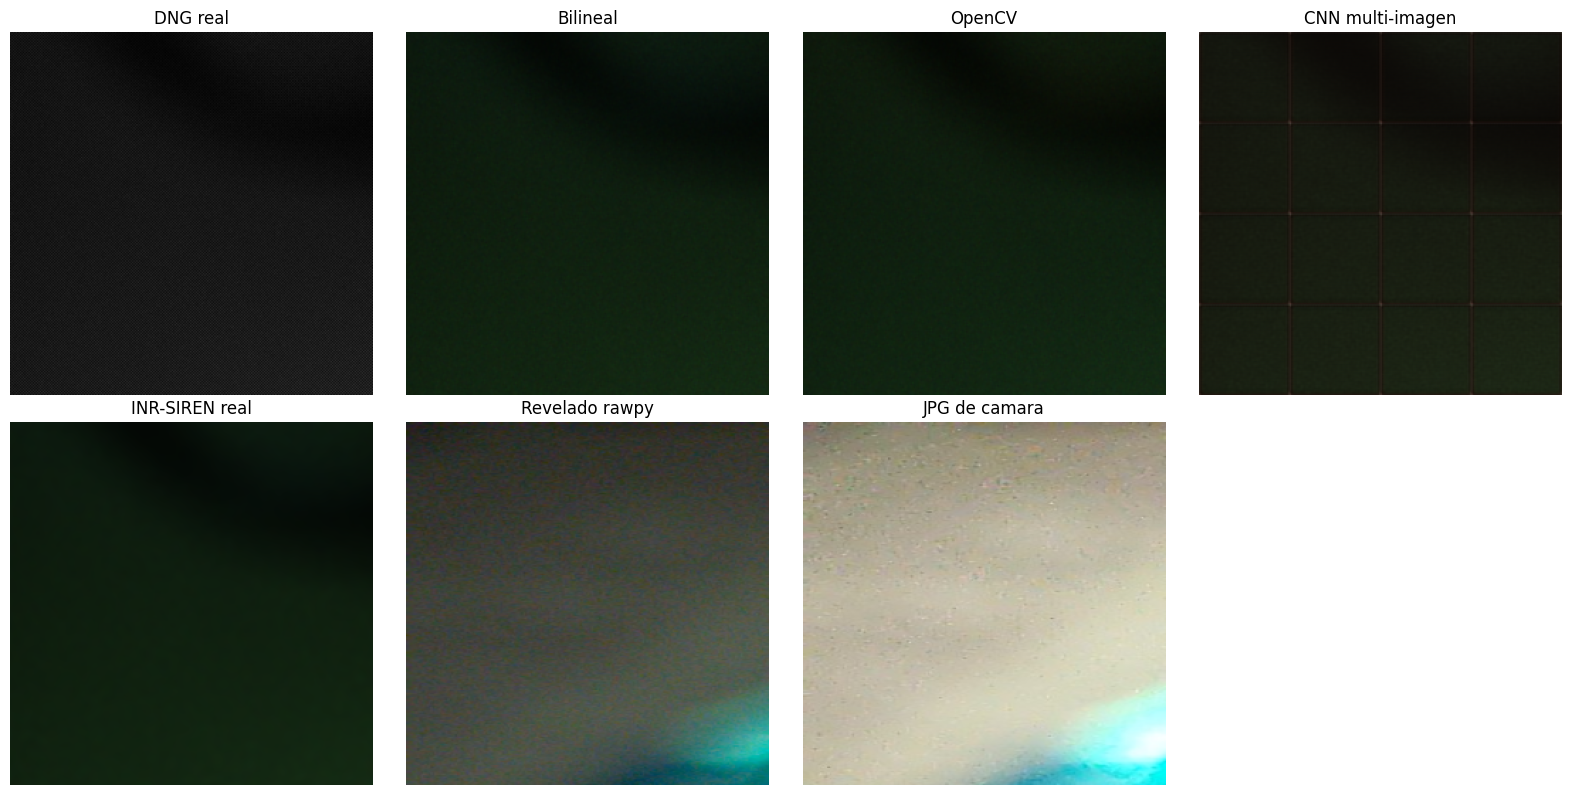

In [14]:
def trim_to_even(image):
    height = image.shape[0] - image.shape[0] % 2
    width = image.shape[1] - image.shape[1] % 2
    return image[:height, :width]

def predict_cnn_on_mosaic(model, mosaic_image, pattern, tile_size=64, overlap=16):
    """Aplica la CNN con solapamiento y promedia las zonas compartidas."""
    if not 0 <= overlap < tile_size:
        raise ValueError("overlap debe estar entre 0 y tile_size - 1")
    mosaic_image = trim_to_even(np.asarray(mosaic_image, dtype=np.float32))
    height, width = mosaic_image.shape
    padded_height = max(height, tile_size)
    padded_width = max(width, tile_size)
    mosaic_padded = np.pad(
        mosaic_image,
        ((0, padded_height - height), (0, padded_width - width)),
        mode="edge",
    )
    masks = bayer_masks(padded_height, padded_width, pattern=pattern)
    reconstruction = np.zeros((padded_height, padded_width, 3), dtype=np.float32)
    weights = np.zeros((padded_height, padded_width, 1), dtype=np.float32)
    stride = tile_size - overlap

    def tile_starts(length):
        starts = list(range(0, max(length - tile_size, 0) + 1, stride))
        last_start = max(length - tile_size, 0)
        if not starts or starts[-1] != last_start:
            starts.append(last_start)
        return starts

    model.eval()
    with torch.no_grad():
        for top in tile_starts(padded_height):
            for left in tile_starts(padded_width):
                mosaic_tile = mosaic_padded[top:top + tile_size, left:left + tile_size]
                mask_tile = masks[top:top + tile_size, left:left + tile_size]
                input_tile = np.concatenate([mosaic_tile[..., None], mask_tile], axis=-1)
                input_tensor = torch.from_numpy(input_tile.transpose(2, 0, 1)[None]).float().to(DEVICE)
                prediction = model(input_tensor)[0].cpu().numpy().transpose(1, 2, 0)
                reconstruction[top:top + tile_size, left:left + tile_size] += prediction
                weights[top:top + tile_size, left:left + tile_size] += 1.0
    reconstruction = reconstruction / np.maximum(weights, 1.0)
    return np.clip(reconstruction[:height, :width], 0.0, 1.0)

real_mosaic = trim_to_even(raw_mosaic_full)
real_bayer = bayer_masks(*real_mosaic.shape, pattern=bayer_pattern)
I_hat_dng_bilinear = demosaic_bilinear(real_mosaic, real_bayer)
I_hat_dng_opencv = demosaic_opencv(real_mosaic, bayer_pattern)
I_hat_dng_cnn = predict_cnn_on_mosaic(model_cnn_kodak, real_mosaic, bayer_pattern)

# La INR se ajusta a un recorte central real para mantener acotado el costo computacional.
INR_REAL_SIZE = min(256, real_mosaic.shape[0], real_mosaic.shape[1])
INR_REAL_SIZE -= INR_REAL_SIZE % 2
crop_top = (real_mosaic.shape[0] - INR_REAL_SIZE) // 2
crop_left = (real_mosaic.shape[1] - INR_REAL_SIZE) // 2
real_mosaic_crop = real_mosaic[crop_top:crop_top + INR_REAL_SIZE, crop_left:crop_left + INR_REAL_SIZE]
real_bayer_crop = bayer_masks(INR_REAL_SIZE, INR_REAL_SIZE, pattern=bayer_pattern)
model_inr_dng, I_hat_dng_inr, dng_inr_loss_history = train_siren_from_mosaic(
    real_mosaic_crop, real_bayer_crop, hidden_features=256, hidden_layers=3, steps=1000
)

def normalize_rgb_image(image):
    image = np.asarray(image, dtype=np.float32)
    if image.max() > 1.0:
        image = image / 255.0
    return np.clip(image, 0.0, 1.0)

def align_rgb_to_raw(image, target_shape):
    image = normalize_rgb_image(image)
    if image.shape[:2] == target_shape:
        aligned = image
    elif image.shape[0] == target_shape[1] and image.shape[1] == target_shape[0]:
        aligned = np.transpose(image, (1, 0, 2))
    else:
        aligned = resize(
            image, target_shape + (3,), anti_aliasing=True, preserve_range=True
        )
    return np.clip(aligned, 0.0, 1.0).astype(np.float32)

camera_reference = align_rgb_to_raw(rgb_from_raw, real_mosaic.shape)
jpg_camera_reference = align_rgb_to_raw(jpg_ref, real_mosaic.shape)

real_crop = np.s_[crop_top:crop_top + INR_REAL_SIZE, crop_left:crop_left + INR_REAL_SIZE]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes[0, 0].imshow(real_mosaic[real_crop], cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("DNG real")
axes[0, 1].imshow(I_hat_dng_bilinear[real_crop])
axes[0, 1].set_title("Bilineal")
axes[0, 2].imshow(I_hat_dng_opencv[real_crop])
axes[0, 2].set_title("OpenCV")
axes[0, 3].imshow(I_hat_dng_cnn[real_crop])
axes[0, 3].set_title("CNN multi-imagen")
axes[1, 0].imshow(I_hat_dng_inr)
axes[1, 0].set_title("INR-SIREN real")
axes[1, 1].imshow(camera_reference[real_crop])
axes[1, 1].set_title("Revelado rawpy")
axes[1, 2].imshow(jpg_camera_reference[real_crop])
axes[1, 2].set_title("JPG de camara")
axes[1, 3].axis("off")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 13. Metricas de evaluacion

Para comparar las reconstrucciones se usaran metricas entre la imagen de referencia $I_{\text{ref}}$ y cada estimacion $\hat{I}$.

### Error cuadratico medio

$$
\operatorname{MSE}(I, \hat{I}) = \frac{1}{3HW}\sum_{i=1}^{H}\sum_{j=1}^{W}\sum_{c=1}^{3}
\left(I_c(i,j) - \hat{I}_c(i,j)\right)^2.
$$

### PSNR

$$
\operatorname{PSNR}(I, \hat{I}) = 10 \log_{10}\left(\frac{\operatorname{MAX}_I^2}{\operatorname{MSE}(I, \hat{I})}\right).
$$

Si las imagenes estan normalizadas en $[0,1]$, entonces $\operatorname{MAX}_I = 1$.

### SSIM

El indice SSIM mide similitud estructural considerando luminancia, contraste y estructura. Se usara como complemento al PSNR, ya que este ultimo no siempre refleja adecuadamente la calidad visual percibida.


In [15]:
# Metricas de calidad
def compute_metrics(reference, estimate):
    reference = np.clip(reference.astype(np.float32), 0.0, 1.0)
    estimate = np.clip(estimate.astype(np.float32), 0.0, 1.0)
    mse = float(np.mean((reference - estimate) ** 2))
    psnr = float(peak_signal_noise_ratio(reference, estimate, data_range=1.0))
    ssim_value = float(ssim(reference, estimate, channel_axis=-1, data_range=1.0))
    return {"MSE": mse, "PSNR [dB]": psnr, "SSIM": ssim_value}

def evaluate_loader_metrics(model, loader):
    rows = []
    model.eval()
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu().numpy().transpose(0, 2, 3, 1)
            targets = targets.numpy().transpose(0, 2, 3, 1)
            for target, prediction in zip(targets, predictions):
                rows.append(compute_metrics(target, prediction))
    return pd.DataFrame(rows).mean(numeric_only=True).to_dict()

def evaluate_classical_loader(loader):
    """Evalua las dos lineas base en exactamente los mismos parches Kodak."""
    bilinear_rows = []
    opencv_rows = []
    for inputs, targets in loader:
        inputs = inputs.numpy()
        targets = targets.numpy().transpose(0, 2, 3, 1)
        for input_image, target in zip(inputs, targets):
            mosaic_image = input_image[0]
            masks = input_image[1:4].transpose(1, 2, 0)
            bilinear_rows.append(compute_metrics(target, demosaic_bilinear(mosaic_image, masks)))
            opencv_rows.append(compute_metrics(target, demosaic_opencv(mosaic_image, bayer_pattern)))
    return (
        pd.DataFrame(bilinear_rows).mean(numeric_only=True).to_dict(),
        pd.DataFrame(opencv_rows).mean(numeric_only=True).to_dict(),
    )

controlled_results_df = pd.DataFrame([
    {"experimento": "Demo JPG sintetico", "metodo": "Bilineal", **compute_metrics(rgb_reference, I_hat_classic)},
    {"experimento": "Demo JPG sintetico", "metodo": "OpenCV", **compute_metrics(rgb_reference, I_hat_opencv)},
    {"experimento": "Demo JPG sintetico", "metodo": "INR-SIREN", **compute_metrics(rgb_reference, I_hat_inr)},
])

kodak_test_metrics = evaluate_loader_metrics(model_cnn_kodak, test_loader)
kodak_bilinear_metrics, kodak_opencv_metrics = evaluate_classical_loader(test_loader)
kodak_results_df = pd.DataFrame([
    {"experimento": "Kodak prueba", "metodo": "Bilineal", **kodak_bilinear_metrics},
    {"experimento": "Kodak prueba", "metodo": "OpenCV", **kodak_opencv_metrics},
    {"experimento": "Kodak prueba", "metodo": "CNN multi-imagen", **kodak_test_metrics}
])

display(controlled_results_df.round(4))
display(kodak_results_df.round(4))


,experimento,metodo,MSE,PSNR [dB],SSIM
0,Demo JPG sintetico,Bilineal,0.0002,36.0545,0.9690
1,Demo JPG sintetico,OpenCV,0.0084,20.7544,0.9053
2,Demo JPG sintetico,INR-SIREN,0.0001,41.0670,0.9791


,experimento,metodo,MSE,PSNR [dB],SSIM
0,Kodak prueba,CNN multi-imagen,0.0008,32.5594,0.9411


## 14. Visualizacion de resultados

La comparacion visual principal corresponde al experimento controlado con `demo.jpg`. La grilla incluye:

1. Imagen RGB de referencia.
2. Medicion mosaico Bayer sintetica.
3. Reconstruccion clasica bilineal.
4. Reconstruccion con representacion implicita.
5. Mapas de error absoluto.

El error absoluto por pixel se define como

$$
E(i,j) = \frac{1}{3}\sum_{c=1}^{3}\left|I_c(i,j)-\hat{I}_c(i,j)\right|.
$$

Al final se incluye una visualizacion aparte del DNG real para mostrar como se ve la medicion cruda del sensor y como difiere de un JPG procesado por camara.


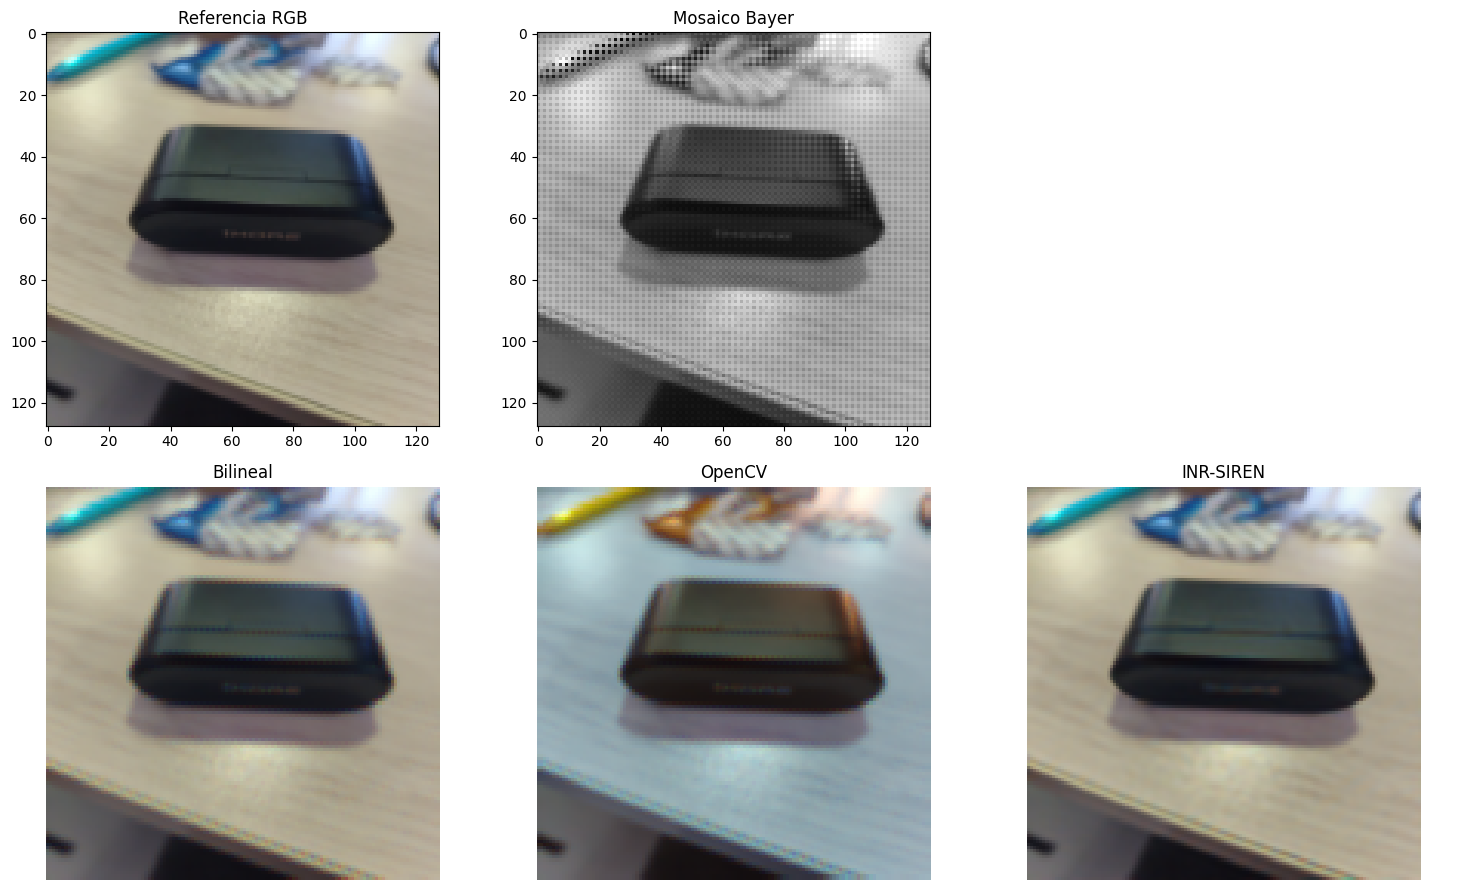

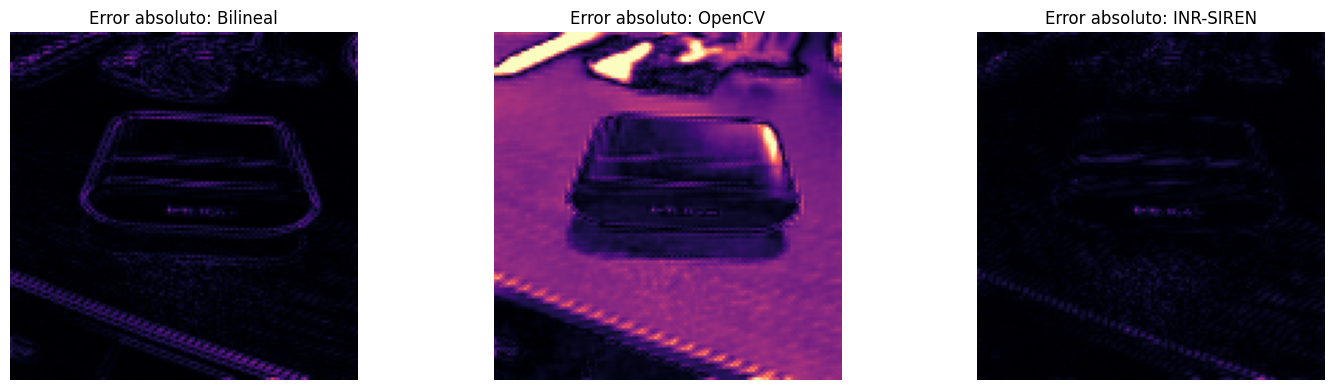

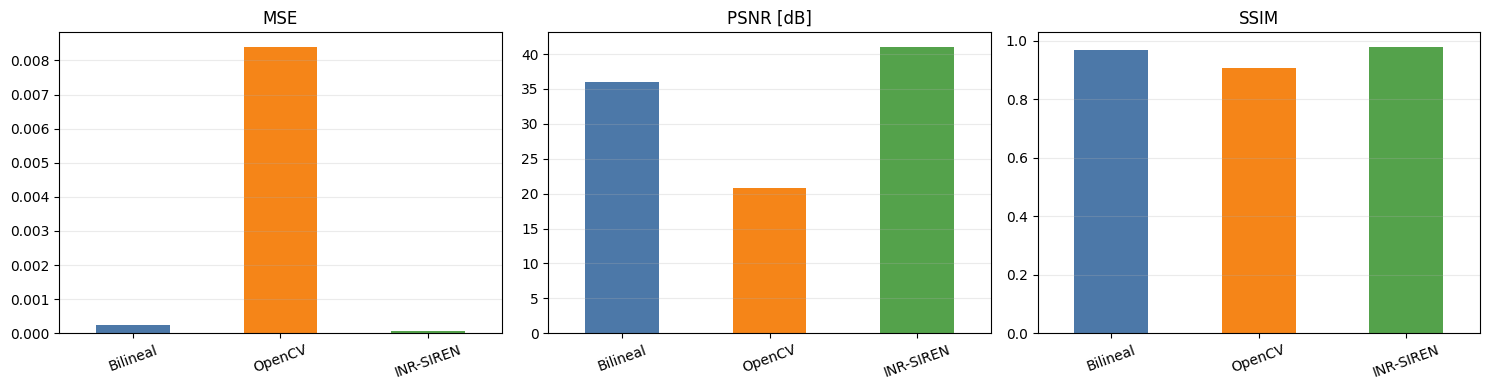

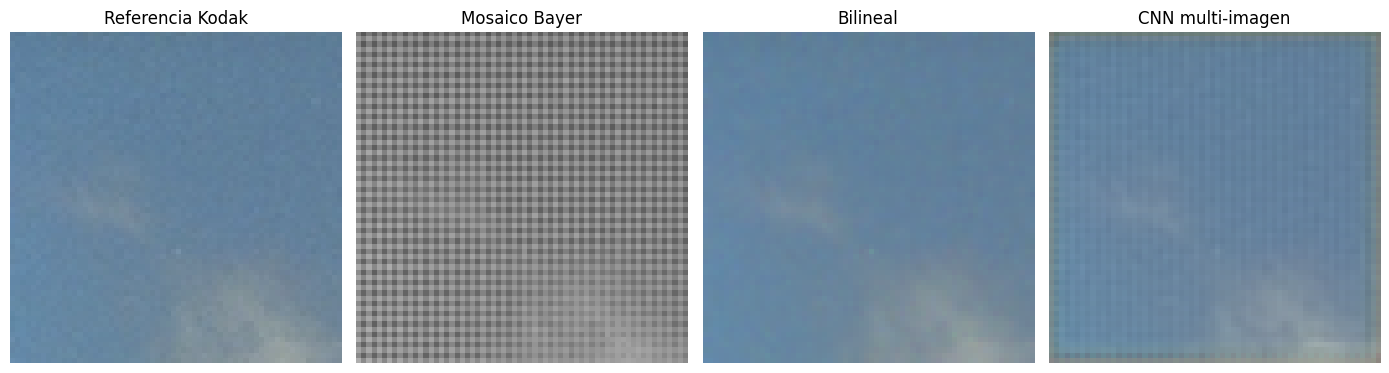

In [16]:
# Visualizacion comparativa
def show_comparison(reference, mosaic, reconstructions, error_scale=5):
    methods = list(reconstructions.keys())
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    axes[0, 0].imshow(reference)
    axes[0, 0].set_title("Referencia RGB")
    axes[0, 1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
    axes[0, 1].set_title("Mosaico Bayer")
    axes[0, 2].axis("off")

    for ax, (method, reconstruction) in zip(axes[1], reconstructions.items()):
        ax.imshow(np.clip(reconstruction, 0, 1))
        ax.set_title(method)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
    for ax, (method, reconstruction) in zip(axes, reconstructions.items()):
        error = np.mean(np.abs(reference - reconstruction), axis=-1)
        ax.imshow(np.clip(error * error_scale, 0, 1), cmap="magma", vmin=0, vmax=1)
        ax.set_title(f"Error absoluto: {method}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

controlled_reconstructions = {
    "Bilineal": I_hat_classic,
    "OpenCV": I_hat_opencv,
    "INR-SIREN": I_hat_inr,
}
show_comparison(rgb_reference, mosaic, controlled_reconstructions)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#4C78A8", "#F58518", "#54A24B"]
for ax, metric in zip(axes, ["MSE", "PSNR [dB]", "SSIM"]):
    controlled_results_df.plot(kind="bar", x="metodo", y=metric, ax=ax, color=colors, legend=False)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Ejemplo de generalizacion sobre un parche Kodak no usado en entrenamiento.
if "model_cnn_kodak" in globals() and len(test_dataset) > 0:
    test_input, test_target = test_dataset[0]
    with torch.no_grad():
        test_prediction = model_cnn_kodak(test_input[None].to(DEVICE))[0].cpu().numpy()
    test_reference = test_target.numpy().transpose(1, 2, 0)
    test_mosaic = test_input[0].numpy()
    test_reconstruction = test_prediction.transpose(1, 2, 0)
    test_masks = bayer_masks(*test_mosaic.shape, pattern=bayer_pattern)
    test_bilinear = demosaic_bilinear(test_mosaic, test_masks)
    test_opencv = demosaic_opencv(test_mosaic, bayer_pattern)

    fig, axes = plt.subplots(1, 5, figsize=(17, 4))
    axes[0].imshow(test_reference)
    axes[0].set_title("Referencia Kodak")
    axes[1].imshow(test_mosaic, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Mosaico Bayer")
    axes[2].imshow(test_bilinear)
    axes[2].set_title("Bilineal")
    axes[3].imshow(test_opencv)
    axes[3].set_title("OpenCV")
    axes[4].imshow(np.clip(test_reconstruction, 0, 1))
    axes[4].set_title("CNN multi-imagen")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()



## 15. Analisis

El experimento principal se realiza con `demo.jpg` como referencia RGB conocida. Desde esa imagen se genera un mosaico Bayer sintetico usando el patron detectado en `demo.dng` (`GRBG` en esta captura). Esto permite evaluar de forma justa los metodos de demosaicking, porque la referencia antes del mosaico es conocida.

La interpolacion bilineal y OpenCV funcionan como lineas base clasicas. La INR-SIREN puede obtener un ajuste muy preciso en una captura especifica, aunque requiere optimizarse nuevamente para cada imagen. La CNN se entrena con varias imagenes Kodak y se compara en el mismo conjunto de prueba contra ambas lineas base, lo que permite evaluar generalizacion de forma mas justa.

La seccion RAW/DNG muestra ademas las reconstrucciones bilineal, OpenCV, CNN multi-imagen e INR-SIREN sobre un recorte central de la captura real. La CNN usa solapamiento entre bloques para disminuir costuras. Como no existe una referencia RGB lineal perfecta asociada al DNG, la comparacion con `rawpy` y el JPG de camara es cualitativa: ambos incluyen decisiones de revelado y procesamiento adicionales.


## 16. Conclusiones

La tarea combina una evaluacion controlada con `demo.jpg`, una comparacion justa en parches Kodak no vistos y una evaluacion cualitativa sobre `demo.dng`. La CNN se entrena con varias imagenes Kodak, se prueba contra las lineas base en imagenes no vistas y luego se aplica al DNG real sin volver a entrenarla. La INR-SIREN se ajusta directamente al recorte central real.

OpenCV y la interpolacion bilineal sirven como lineas base. Las diferencias entre el revelado de la camara y las reconstrucciones neuronales deben interpretarse con cautela, ya que el JPG no es una verdad de terreno lineal del sensor.
